<a href="https://colab.research.google.com/github/heitorabqg/datascientist/blob/master/fineTunningDeepRadar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# 1) Verificar ambiente
import os, sys, json, math, random, shutil, subprocess, glob
from pathlib import Path

import torch
print("PyTorch:", torch.__version__)
print("CUDA disponível:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)


PyTorch: 2.11.0+cu128
CUDA disponível: True
GPU: Tesla T4
Device: cuda


In [3]:
# 2) Instalar dependências leves
!pip -q install kagglehub h5py scikit-learn tqdm

In [4]:
import os
import sys
import json
import math
import random
import shutil
from pathlib import Path

import numpy as np
import torch
from pathlib import Path
# =========================
# CONFIGURAÇÃO
# =========================
SEED = 42

# Dataset Kaggle
# Slug esperado a partir da página mencionada anteriormente:
KAGGLE_DATASET = "khilian/deepradar"

# 1%=0.01, 5%=0.05, 10%=0.10, completo=1.0
SUBSET_FRACTION = 0.01
VAL_FRACTION = 0.20
NUM_CLASSES = 23

# STFT
N_FFT = 128
HOP_LENGTH = 32
WIN_LENGTH = 128
IMAGE_SIZE = 224

# LoRA
RANK_METHOD = "energy"   # "fixed", "energy", "effective_rank"
FIXED_RANK = 8
MIN_RANK = 1
MAX_RANK = 16
ENERGY_THRESHOLD = 0.95
LORA_ALPHA = 16.0
LORA_DROPOUT = 0.05

# Calibração
CALIBRATION_BATCHES = 5

# Treinamento
BATCH_SIZE = 8
EPOCHS = 3
LR = 3e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2

# Resultados locais temporários
OUTPUT_DIR = Path("/content/deepradar_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Subset:", SUBSET_FRACTION)
print("Rank method:", RANK_METHOD)


Subset: 0.01
Rank method: energy


In [5]:
import kagglehub

dataset_path = kagglehub.dataset_download(KAGGLE_DATASET)
DATA_ROOT = Path(dataset_path)

print("Dataset baixado em:", DATA_ROOT)
print("\nPrimeiros arquivos encontrados:")
all_files = [p for p in DATA_ROOT.rglob("*") if p.is_file()]
for p in all_files[:50]:
    print(" -", p.relative_to(DATA_ROOT))
print("\nTotal de arquivos:", len(all_files))


100%|██████████| 11.4G/11.4G [02:17<00:00, 89.2MB/s]

Extracting files...


Dataset baixado em: /root/.cache/kagglehub/datasets/khilian/deepradar/versions/1

Primeiros arquivos encontrados:
 - lbl_train.mat
 - Y_train.mat
 - lbl_val.mat
 - lbl_test.mat
 - X_test.mat
 - Y_val.mat
 - X_val.mat
 - Y_test.mat
 - X_train.mat

Total de arquivos: 9


In [10]:
from pathlib import Path

x_train_path = Path(
    "/root/.cache/kagglehub/datasets/khilian/deepradar/versions/1/X_train.mat"
)

print("Arquivo:", x_train_path)
print("Existe:", x_train_path.exists())

Arquivo: /root/.cache/kagglehub/datasets/khilian/deepradar/versions/1/X_train.mat
Existe: True


In [11]:
import h5py

print("Arquivo:", x_train_path)

with h5py.File(x_train_path, "r") as f:

    print("\nChaves principais:")
    print(list(f.keys()))

    print("\nEstrutura completa:")

    def mostrar(nome, objeto):

        if isinstance(objeto, h5py.Dataset):
            print(
                f"DATASET: {nome} | "
                f"shape={objeto.shape} | "
                f"dtype={objeto.dtype}"
            )

        elif isinstance(objeto, h5py.Group):
            print(f"GRUPO: {nome}")

    f.visititems(mostrar)

Arquivo: /root/.cache/kagglehub/datasets/khilian/deepradar/versions/1/X_train.mat

Chaves principais:
['X_train']

Estrutura completa:
DATASET: X_train | shape=(2, 1024, 469200) | dtype=float64


In [12]:
import h5py
import numpy as np

with h5py.File(x_train_path, "r") as f:

    X = f["X_train"]

    print("Dataset completo:", X.shape)

    # Ler SOMENTE o primeiro sinal
    signal = np.asarray(
        X[:, :, 0],
        dtype=np.float32
    )

print("Shape de um sinal:", signal.shape)

print("Canal I:", signal[0].shape)
print("Canal Q:", signal[1].shape)

Dataset completo: (2, 1024, 469200)
Shape de um sinal: (2, 1024)
Canal I: (1024,)
Canal Q: (1024,)


In [13]:
import h5py
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import scipy.io as sio


class DeepRadarLazyDataset(Dataset):

    def __init__(
        self,
        x_path,
        y_path,
        x_key="X_train",
        y_key="Y_train",
        indices=None,
        transform=None
    ):
        self.x_path = str(x_path)
        self.y_path = str(y_path)

        self.x_key = x_key
        self.y_key = y_key

        self.transform = transform

        # --------------------------------------------
        # Carrega SOMENTE os labels na memória
        # --------------------------------------------
        labels_mat = sio.loadmat(self.y_path)

        print("Chaves do arquivo de labels:")
        print(labels_mat.keys())

        Y = labels_mat[self.y_key]

        # Se labels forem one-hot
        if Y.ndim == 2 and Y.shape[1] > 1:
            self.labels = np.argmax(Y, axis=1)
        else:
            self.labels = Y.reshape(-1)

        # --------------------------------------------
        # Índices utilizados pelo subset
        # --------------------------------------------
        if indices is None:
            self.indices = np.arange(len(self.labels))
        else:
            self.indices = np.asarray(indices)

        # O arquivo HDF5 será aberto somente quando
        # o DataLoader começar a solicitar amostras.
        self._h5_file = None
        self._x_dataset = None

    def __len__(self):

        return len(self.indices)

    def _open_file(self):

        if self._h5_file is None:

            self._h5_file = h5py.File(
                self.x_path,
                "r"
            )

            self._x_dataset = self._h5_file[
                self.x_key
            ]

    def __getitem__(self, item):

        self._open_file()

        idx = int(
            self.indices[item]
        )

        # --------------------------------------------
        # LEITURA LAZY
        #
        # Arquivo:
        #
        # (2, 1024, 469200)
        #
        # Lemos apenas:
        #
        # (2, 1024)
        # --------------------------------------------

        iq = np.asarray(
            self._x_dataset[
                :, :, idx
            ],
            dtype=np.float32
        )

        label = int(
            self.labels[idx]
        )

        if self.transform is not None:

            iq = self.transform(
                iq
            )

        return iq, label

In [14]:
import numpy as np

# Quantidade total de amostras de treino
N_TRAIN = 469200

# Fração que queremos usar
SUBSET_FRACTION = 0.01

# Número de amostras
n_subset = int(
    N_TRAIN * SUBSET_FRACTION
)

print(
    "Total treino:",
    N_TRAIN
)

print(
    "Subset:",
    n_subset
)

# Índices aleatórios
rng = np.random.default_rng(
    seed=42
)

train_idx = rng.choice(
    N_TRAIN,
    size=n_subset,
    replace=False
)

print(
    "Quantidade de índices:",
    len(train_idx)
)

print(
    "Primeiros índices:",
    train_idx[:10]
)

Total treino: 469200
Subset: 4692
Quantidade de índices: 4692
Primeiros índices: [236453 208851   5645 414871 132406  70116  69827 257916 232801  77095]


In [15]:
import numpy as np
import torch
import torch.nn.functional as F


class IQToSpectrogram:

    def __init__(
        self,
        n_fft=128,
        hop_length=32,
        win_length=128,
        image_size=224
    ):

        self.n_fft = n_fft
        self.hop_length = hop_length
        self.win_length = win_length
        self.image_size = image_size

        self.window = torch.hann_window(
            win_length
        )

    def __call__(self, iq):

        # Converte numpy -> tensor
        iq = torch.as_tensor(
            iq,
            dtype=torch.float32
        )

        # DeepRadar:
        #
        # iq.shape = (2, 1024)
        #
        # iq[0] = I
        # iq[1] = Q

        I = iq[0]

        Q = iq[1]

        # Sinal complexo
        signal = torch.complex(
            I,
            Q
        )

        # STFT
        Z = torch.stft(

            signal,

            n_fft=self.n_fft,

            hop_length=self.hop_length,

            win_length=self.win_length,

            window=self.window,

            return_complex=True,

            center=True
        )

        # Magnitude
        magnitude = torch.abs(
            Z
        )

        # Escala log
        spectrogram = torch.log10(
            magnitude + 1e-10
        )

        # Centralizar frequência
        spectrogram = torch.fft.fftshift(
            spectrogram,
            dim=0
        )

        # Normalização
        spectrogram = (

            spectrogram
            -
            spectrogram.mean()

        ) / (

            spectrogram.std()
            +
            1e-6

        )

        # Adiciona dimensões:
        #
        # (freq, tempo)
        #
        # ->
        #
        # (1,1,freq,tempo)

        spectrogram = spectrogram.unsqueeze(
            0
        ).unsqueeze(
            0
        )

        # Resize para ViT
        spectrogram = F.interpolate(

            spectrogram,

            size=(
                self.image_size,
                self.image_size
            ),

            mode="bilinear",

            align_corners=False
        )

        # Remove dimensão batch
        spectrogram = spectrogram.squeeze(
            0
        )

        # ViT espera RGB:
        #
        # (1,224,224)
        #
        # ->
        #
        # (3,224,224)

        spectrogram = spectrogram.repeat(
            3,
            1,
            1
        )

        return spectrogram

In [16]:
transform = IQToSpectrogram(

    n_fft=128,

    hop_length=32,

    win_length=128,

    image_size=224
)

In [17]:
import h5py

with h5py.File(
    x_train_path,
    "r"
) as f:

    signal = np.asarray(

        f["X_train"][
            :, :, 0
        ],

        dtype=np.float32
    )


print(
    "Antes da STFT:",
    signal.shape
)

spectrogram = transform(
    signal
)

print(
    "Depois da STFT:",
    spectrogram.shape
)

Antes da STFT: (2, 1024)
Depois da STFT: torch.Size([3, 224, 224])


In [19]:
from pathlib import Path

DATA_ROOT = Path(
    "/root/.cache/kagglehub/datasets/khilian/deepradar/versions/1"
)

x_train_path = DATA_ROOT / "X_train.mat"
y_train_path = DATA_ROOT / "Y_train.mat"

print("X_train:", x_train_path)
print("Existe:", x_train_path.exists())

print("Y_train:", y_train_path)
print("Existe:", y_train_path.exists())

X_train: /root/.cache/kagglehub/datasets/khilian/deepradar/versions/1/X_train.mat
Existe: True
Y_train: /root/.cache/kagglehub/datasets/khilian/deepradar/versions/1/Y_train.mat
Existe: True


In [20]:
train_dataset = DeepRadarLazyDataset(

    x_path=x_train_path,

    y_path=y_train_path,

    x_key="X_train",

    y_key="Y_train",

    indices=train_idx,

    transform=transform
)

Chaves do arquivo de labels:
dict_keys(['__header__', '__version__', '__globals__', 'Y_train'])


In [21]:
train_loader = DataLoader(

    train_dataset,

    batch_size=8,

    shuffle=True,

    num_workers=0,

    pin_memory=torch.cuda.is_available()
)

In [22]:
xb, yb = next(
    iter(train_loader)
)

print(
    "Batch X:",
    xb.shape
)

print(
    "Batch y:",
    yb.shape
)

print(
    "Labels:",
    yb
)

Batch X: torch.Size([8, 3, 224, 224])
Batch y: torch.Size([8])
Labels: tensor([19, 17, 11, 14,  2,  3,  8, 11])


In [30]:
from torch import nn
from torchvision.models import vit_b_16, ViT_B_16_Weights

def build_vit(num_classes):
    model = vit_b_16(weights=ViT_B_16_Weights.DEFAULT)

    for p in model.parameters():
        p.requires_grad = False

    in_features = model.heads.head.in_features
    model.heads.head = nn.Linear(in_features, num_classes)
    return model

model = build_vit(NUM_CLASSES)
print("Modelo criado.")


Modelo criado.


In [31]:
def energy_rank(matrix, energy_threshold=0.95, min_rank=1, max_rank=16):
    matrix = matrix.detach().float().cpu()
    if matrix.ndim != 2:
        matrix = matrix.reshape(matrix.shape[0], -1)

    s = torch.linalg.svdvals(matrix)
    energy = s.square()

    if energy.sum() <= 0:
        return min_rank

    cumulative = torch.cumsum(energy, dim=0) / energy.sum()
    idx = torch.nonzero(cumulative >= energy_threshold, as_tuple=False)
    r = int(idx[0].item()) + 1 if len(idx) else max_rank
    return max(min_rank, min(max_rank, r))


def effective_rank(matrix, min_rank=1, max_rank=16):
    matrix = matrix.detach().float().cpu()
    s = torch.linalg.svdvals(matrix)
    p = s / (s.sum() + 1e-12)
    entropy = -(p * torch.log(p + 1e-12)).sum()
    r = int(round(torch.exp(entropy).item()))
    return max(min_rank, min(max_rank, r))


def compute_adaptive_rank(matrix, method="energy"):
    # ================================================================
    # ⭐⭐⭐⭐⭐⭐⭐⭐⭐ SUA MÉTRICA ENTRA AQUI ⭐⭐⭐⭐⭐⭐⭐⭐⭐
    #
    # Exemplo futuro:
    #
    # if method == "my_metric":
    #     return minha_metrica(
    #         matrix,
    #         min_rank=MIN_RANK,
    #         max_rank=MAX_RANK
    #     )
    #
    # Você pode substituir a análise espectral por:
    # - gradientes
    # - ativações
    # - entropia
    # - stable rank
    # - combinação gradiente + ativação
    # - uma métrica própria
    # ================================================================

    if method == "energy":
        return energy_rank(
            matrix,
            energy_threshold=ENERGY_THRESHOLD,
            min_rank=MIN_RANK,
            max_rank=MAX_RANK,
        )

    if method == "effective_rank":
        return effective_rank(matrix, MIN_RANK, MAX_RANK)

    if method == "fixed":
        return FIXED_RANK

    raise ValueError(f"Método desconhecido: {method}")


In [32]:
def collect_gradient_proxies(model, loader, device, num_batches=5):
    candidates = {
        name: module
        for name, module in model.named_modules()
        if isinstance(module, nn.Linear) and name.startswith("encoder.layers")
    }

    old_flags = {}
    for name, module in candidates.items():
        old_flags[name] = module.weight.requires_grad
        module.weight.requires_grad_(True)

    criterion = nn.CrossEntropyLoss()
    accum = {
        name: torch.zeros_like(module.weight, device="cpu")
        for name, module in candidates.items()
    }
    counts = {name: 0 for name in candidates}

    model.to(device)
    model.train()

    for batch_idx, (x, labels) in enumerate(loader):
        if batch_idx >= num_batches:
            break

        print(f"Calibração {batch_idx+1}/{num_batches}")
        x = x.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        model.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, labels)
        loss.backward()

        for name, module in candidates.items():
            if module.weight.grad is not None:
                accum[name] += module.weight.grad.detach().abs().cpu()
                counts[name] += 1

    for name, module in candidates.items():
        module.weight.requires_grad_(old_flags[name])

    return {
        name: accum[name] / max(counts[name], 1)
        for name in accum if counts[name] > 0
    }

gradient_proxies = collect_gradient_proxies(
    model, train_loader, DEVICE, CALIBRATION_BATCHES
)

rank_map = {
    name: compute_adaptive_rank(matrix, RANK_METHOD)
    for name, matrix in gradient_proxies.items()
}

print("\nRanks selecionados:")
for name, rank in rank_map.items():
    print(f"{name}: r={rank}")

if rank_map:
    print("\nRank médio:", np.mean(list(rank_map.values())))


Calibração 1/5
Calibração 2/5
Calibração 3/5
Calibração 4/5
Calibração 5/5

Ranks selecionados:
encoder.layers.encoder_layer_0.self_attention.out_proj: r=1
encoder.layers.encoder_layer_0.mlp.0: r=5
encoder.layers.encoder_layer_0.mlp.3: r=3
encoder.layers.encoder_layer_1.self_attention.out_proj: r=1
encoder.layers.encoder_layer_1.mlp.0: r=5
encoder.layers.encoder_layer_1.mlp.3: r=4
encoder.layers.encoder_layer_2.self_attention.out_proj: r=3
encoder.layers.encoder_layer_2.mlp.0: r=5
encoder.layers.encoder_layer_2.mlp.3: r=2
encoder.layers.encoder_layer_3.self_attention.out_proj: r=3
encoder.layers.encoder_layer_3.mlp.0: r=3
encoder.layers.encoder_layer_3.mlp.3: r=3
encoder.layers.encoder_layer_4.self_attention.out_proj: r=3
encoder.layers.encoder_layer_4.mlp.0: r=3
encoder.layers.encoder_layer_4.mlp.3: r=4
encoder.layers.encoder_layer_5.self_attention.out_proj: r=4
encoder.layers.encoder_layer_5.mlp.0: r=5
encoder.layers.encoder_layer_5.mlp.3: r=7
encoder.layers.encoder_layer_6.self_atte

In [33]:
import math
import torch
from torch import nn


class LoRALinear(nn.Module):

    def __init__(
        self,
        base,
        rank=8,
        alpha=16.0,
        dropout=0.0
    ):
        super().__init__()

        self.base = base

        self.rank = int(rank)
        self.alpha = float(alpha)

        self.scaling = (
            self.alpha / self.rank
        )

        self.dropout = nn.Dropout(
            dropout
        )

        # Congela camada original
        for param in self.base.parameters():
            param.requires_grad = False

        # LoRA A
        self.lora_A = nn.Parameter(
            torch.empty(
                self.rank,
                base.in_features
            )
        )

        # LoRA B
        self.lora_B = nn.Parameter(
            torch.zeros(
                base.out_features,
                self.rank
            )
        )

        nn.init.kaiming_uniform_(
            self.lora_A,
            a=math.sqrt(5)
        )


    # ==========================================
    # Compatibilidade com nn.Linear
    # ==========================================

    @property
    def weight(self):
        return self.base.weight


    @property
    def bias(self):
        return self.base.bias


    @property
    def in_features(self):
        return self.base.in_features


    @property
    def out_features(self):
        return self.base.out_features


    def forward(self, x):

        # Saída original
        base_output = self.base(x)

        # Atualização LoRA
        lora_output = (
            self.dropout(x)
            @ self.lora_A.T
            @ self.lora_B.T
        )

        return (
            base_output
            +
            self.scaling
            *
            lora_output
        )

In [36]:
import h5py
import scipy.io as sio


with h5py.File(
    x_val_path,
    "r"
) as f:

    print(
        "Chaves X_val:",
        list(f.keys())
    )


labels_val = sio.loadmat(
    y_val_path
)

print(
    "Chaves Y_val:",
    labels_val.keys()
)

Chaves X_val: ['X_val']
Chaves Y_val: dict_keys(['__header__', '__version__', '__globals__', 'Y_val'])


In [37]:
import numpy as np

N_VAL = 156400

VAL_SUBSET_FRACTION = 0.01

n_val_subset = int(
    N_VAL
    *
    VAL_SUBSET_FRACTION
)

rng = np.random.default_rng(
    42
)

val_idx = rng.choice(
    N_VAL,
    size=n_val_subset,
    replace=False
)

print(
    "Validação completa:",
    N_VAL
)

print(
    "Subset validação:",
    len(val_idx)
)

Validação completa: 156400
Subset validação: 1564


In [38]:
val_dataset = DeepRadarLazyDataset(

    x_path=x_val_path,

    y_path=y_val_path,

    x_key="X_val",

    y_key="Y_val",

    indices=val_idx,

    transform=transform
)

Chaves do arquivo de labels:
dict_keys(['__header__', '__version__', '__globals__', 'Y_val'])


In [39]:
val_loader = DataLoader(

    val_dataset,

    batch_size=8,

    shuffle=False,

    num_workers=0,

    pin_memory=torch.cuda.is_available()
)

In [40]:
xb_val, yb_val = next(
    iter(val_loader)
)

print(
    "Val X:",
    xb_val.shape
)

print(
    "Val Y:",
    yb_val.shape
)

print(
    "Labels:",
    yb_val
)

Val X: torch.Size([8, 3, 224, 224])
Val Y: torch.Size([8])
Labels: tensor([ 6,  3, 18, 19, 16, 22, 15, 18])


In [35]:
from pathlib import Path

DATA_ROOT = Path(
    "/root/.cache/kagglehub/datasets/khilian/deepradar/versions/1"
)

x_val_path = DATA_ROOT / "X_val.mat"
y_val_path = DATA_ROOT / "Y_val.mat"

print(
    "X_val existe:",
    x_val_path.exists()
)

print(
    "Y_val existe:",
    y_val_path.exists()
)

X_val existe: True
Y_val existe: True


In [41]:
from tqdm.auto import tqdm

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=LR,
    weight_decay=WEIGHT_DECAY,
)

model.to(DEVICE)
history = []
best_acc = -1.0

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    correct = 0
    total_seen = 0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}")

    for x, labels in pbar:
        x = x.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total_seen += labels.size(0)

        pbar.set_postfix(
            loss=running_loss/max(total_seen,1),
            acc=correct/max(total_seen,1)
        )

    # Validação
    model.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for x, labels in val_loader:
            x = x.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            pred = model(x).argmax(1)
            val_correct += (pred == labels).sum().item()
            val_total += labels.size(0)

    row = {
        "epoch": epoch,
        "train_loss": running_loss / max(total_seen, 1),
        "train_accuracy": correct / max(total_seen, 1),
        "val_accuracy": val_correct / max(val_total, 1),
    }
    history.append(row)
    print(row)

    if row["val_accuracy"] > best_acc:
        best_acc = row["val_accuracy"]
        torch.save(model.state_dict(), OUTPUT_DIR / "best_model.pt")

print("Melhor validation accuracy:", best_acc)


Epoch 1/3:   0%|          | 0/587 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 1.8953322291069323, 'train_accuracy': 0.37851662404092073, 'val_accuracy': 0.39514066496163686}


Epoch 2/3:   0%|          | 0/587 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 1.7544237953521, 'train_accuracy': 0.4185848252344416, 'val_accuracy': 0.43861892583120204}


Epoch 3/3:   0%|          | 0/587 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 1.6627752585789126, 'train_accuracy': 0.4486359761295823, 'val_accuracy': 0.440537084398977}
Melhor validation accuracy: 0.440537084398977


In [42]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

model.load_state_dict(torch.load(OUTPUT_DIR / "best_model.pt", map_location=DEVICE))
model.eval()

ys = []
preds = []

with torch.no_grad():
    for x, labels in tqdm(val_loader, desc="Avaliando"):
        logits = model(x.to(DEVICE, non_blocking=True))
        pred = logits.argmax(1).cpu().numpy()
        ys.append(labels.numpy())
        preds.append(pred)

y_true = np.concatenate(ys)
y_pred = np.concatenate(preds)

accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")

print("Accuracy:", accuracy)
print("Macro-F1:", macro_f1)
print("\nRelatório:")
print(classification_report(y_true, y_pred, zero_division=0))


Avaliando:   0%|          | 0/196 [00:00<?, ?it/s]

Accuracy: 0.440537084398977
Macro-F1: 0.4129218452441133

Relatório:
              precision    recall  f1-score   support

           0       1.00      0.91      0.95        69
           1       0.65      0.33      0.43        61
           2       0.46      0.56      0.50        81
           3       0.88      0.55      0.67        77
           4       0.59      0.36      0.45        47
           5       0.38      0.16      0.23        67
           6       0.32      0.10      0.15        73
           7       0.22      0.36      0.27        69
           8       0.31      0.28      0.30        46
           9       0.79      0.74      0.76        70
          10       0.40      0.20      0.27        79
          11       0.33      0.05      0.09        77
          12       0.24      0.71      0.36        72
          13       0.33      0.28      0.30        57
          14       0.29      0.12      0.17        68
          15       0.38      0.62      0.47        66
          16

In [43]:
results = {
    "kaggle_dataset": KAGGLE_DATASET,
    "subset_fraction": SUBSET_FRACTION,
    "rank_method": RANK_METHOD,
    "fixed_rank": FIXED_RANK,
    "energy_threshold": ENERGY_THRESHOLD,
    "min_rank": MIN_RANK,
    "max_rank": MAX_RANK,
    "rank_map": rank_map,
    "rank_mean": float(np.mean(list(rank_map.values()))) if rank_map else None,
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "trainable_parameters": int(trainable),
    "total_parameters": int(total),
    "history": history,
}

with open(OUTPUT_DIR / "results.json", "w") as f:
    json.dump(results, f, indent=2)

np.save(OUTPUT_DIR / "confusion_matrix.npy", confusion_matrix(y_true, y_pred))

print("Resultados salvos em:", OUTPUT_DIR)
print(list(OUTPUT_DIR.iterdir()))


Resultados salvos em: /content/deepradar_results
[PosixPath('/content/deepradar_results/results.json'), PosixPath('/content/deepradar_results/confusion_matrix.npy'), PosixPath('/content/deepradar_results/best_model.pt')]


In [44]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("/content/deepradar_results")

# ==============================
# Carregar resultados
# ==============================

with open(
    OUTPUT_DIR / "results.json",
    "r"
) as f:
    results = json.load(f)

print("=== RESULTADOS DO EXPERIMENTO ===")

print(
    "Método de rank:",
    results["rank_method"]
)

print(
    "Fração do dataset:",
    results["subset_fraction"]
)

print(
    "Accuracy:",
    results["accuracy"]
)

print(
    "Macro-F1:",
    results["macro_f1"]
)

print(
    "Rank médio:",
    results["rank_mean"]
)

print(
    "Parâmetros treináveis:",
    results["trainable_parameters"]
)

print(
    "Parâmetros totais:",
    results["total_parameters"]
)

=== RESULTADOS DO EXPERIMENTO ===
Método de rank: energy
Fração do dataset: 0.01
Accuracy: 0.440537084398977
Macro-F1: 0.4129218452441133
Rank médio: 4.444444444444445
Parâmetros treináveis: 476183
Parâmetros totais: 86274839


,epoch,train_loss,train_accuracy,val_accuracy
0,1,1.895332,0.378517,0.395141
1,2,1.754424,0.418585,0.438619
2,3,1.662775,0.448636,0.440537


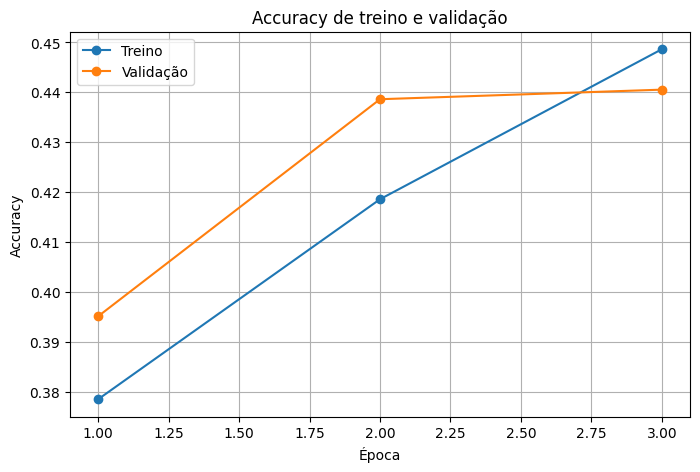

In [45]:
history = pd.DataFrame(
    results["history"]
)

display(history)

plt.figure(figsize=(8, 5))

plt.plot(
    history["epoch"],
    history["train_accuracy"],
    marker="o",
    label="Treino"
)

plt.plot(
    history["epoch"],
    history["val_accuracy"],
    marker="o",
    label="Validação"
)

plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.title(
    "Accuracy de treino e validação"
)

plt.legend()
plt.grid(True)

plt.show()

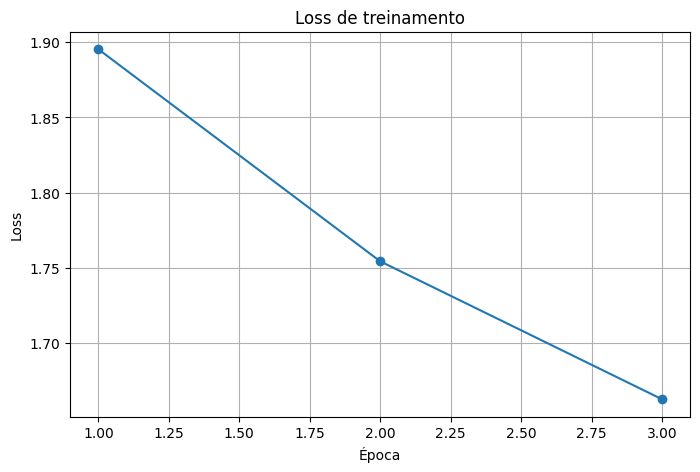

In [46]:
plt.figure(figsize=(8, 5))

plt.plot(
    history["epoch"],
    history["train_loss"],
    marker="o"
)

plt.xlabel("Época")
plt.ylabel("Loss")
plt.title(
    "Loss de treinamento"
)

plt.grid(True)

plt.show()

In [47]:
rank_map = results["rank_map"]

rank_df = pd.DataFrame(
    list(rank_map.items()),
    columns=[
        "Camada",
        "Rank"
    ]
)

display(rank_df)

print(
    "Rank mínimo:",
    rank_df["Rank"].min()
)

print(
    "Rank máximo:",
    rank_df["Rank"].max()
)

print(
    "Rank médio:",
    rank_df["Rank"].mean()
)

print(
    "Mediana:",
    rank_df["Rank"].median()
)

,Camada,Rank
0,encoder.layers.encoder_layer_0.self_attention....,1
1,encoder.layers.encoder_layer_0.mlp.0,5
2,encoder.layers.encoder_layer_0.mlp.3,3
3,encoder.layers.encoder_layer_1.self_attention....,1
4,encoder.layers.encoder_layer_1.mlp.0,5
5,encoder.layers.encoder_layer_1.mlp.3,4
6,encoder.layers.encoder_layer_2.self_attention....,3
7,encoder.layers.encoder_layer_2.mlp.0,5
8,encoder.layers.encoder_layer_2.mlp.3,2
9,encoder.layers.encoder_layer_3.self_attention....,3


Rank mínimo: 1
Rank máximo: 14
Rank médio: 4.444444444444445
Mediana: 4.0


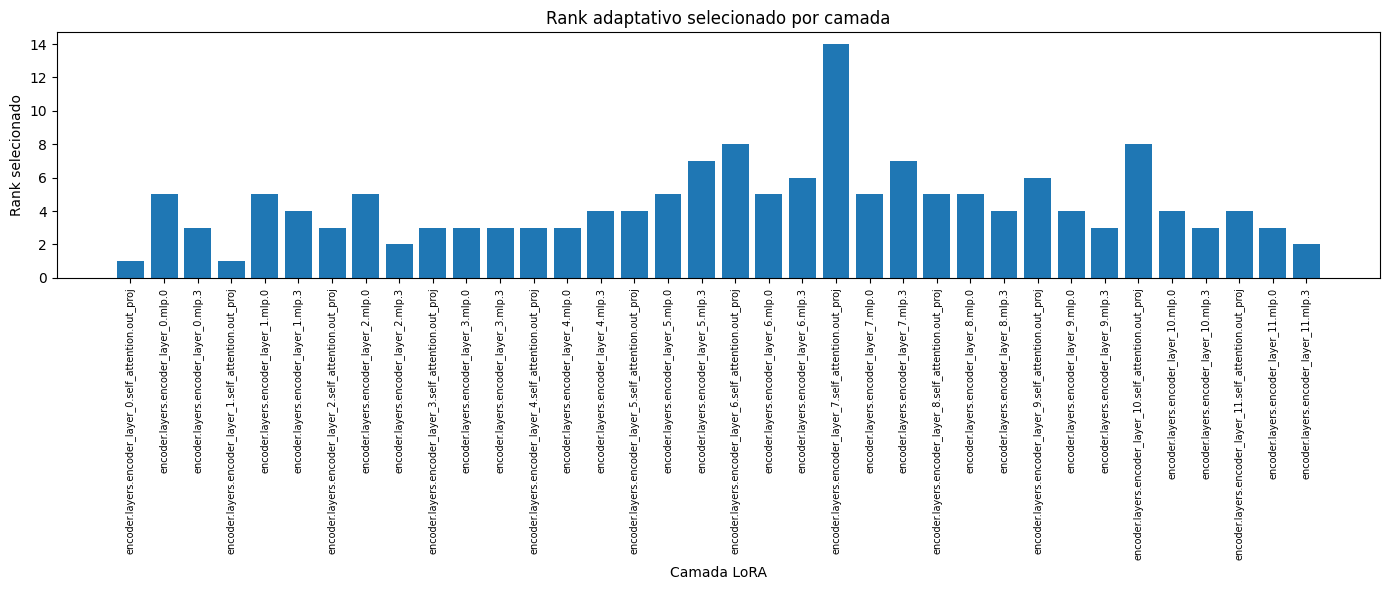

In [48]:
plt.figure(
    figsize=(14, 6)
)

plt.bar(
    range(len(rank_df)),
    rank_df["Rank"]
)

plt.xlabel(
    "Camada LoRA"
)

plt.ylabel(
    "Rank selecionado"
)

plt.title(
    "Rank adaptativo selecionado por camada"
)

plt.xticks(
    range(len(rank_df)),
    rank_df["Camada"],
    rotation=90,
    fontsize=7
)

plt.tight_layout()

plt.show()

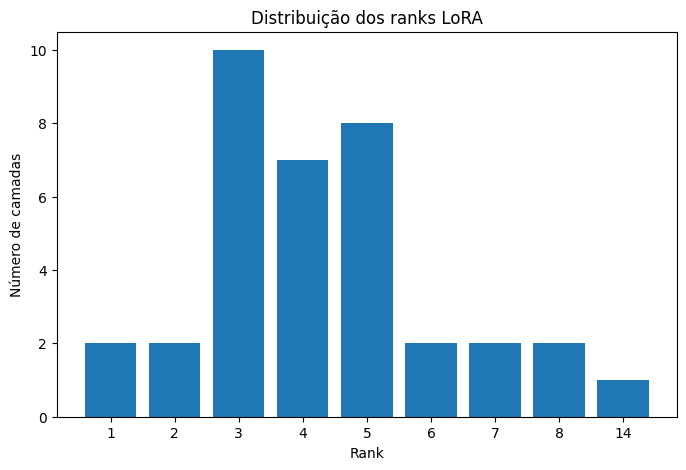

Rank
1      2
2      2
3     10
4      7
5      8
6      2
7      2
8      2
14     1
Name: count, dtype: int64


In [49]:
rank_counts = (
    rank_df["Rank"]
    .value_counts()
    .sort_index()
)

plt.figure(
    figsize=(8, 5)
)

plt.bar(
    rank_counts.index.astype(str),
    rank_counts.values
)

plt.xlabel(
    "Rank"
)

plt.ylabel(
    "Número de camadas"
)

plt.title(
    "Distribuição dos ranks LoRA"
)

plt.show()

print(rank_counts)

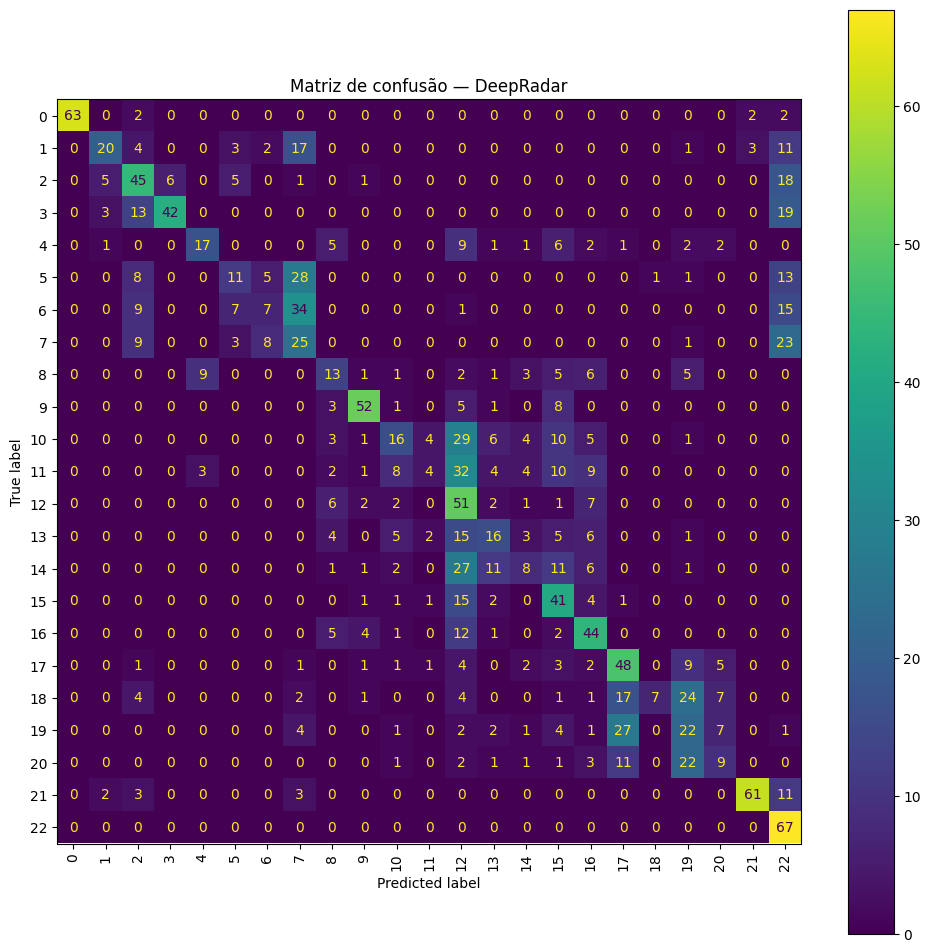

In [50]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = np.load(
    OUTPUT_DIR /
    "confusion_matrix.npy"
)

fig, ax = plt.subplots(
    figsize=(12, 12)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    values_format="d"
)

plt.title(
    "Matriz de confusão — DeepRadar"
)

plt.show()

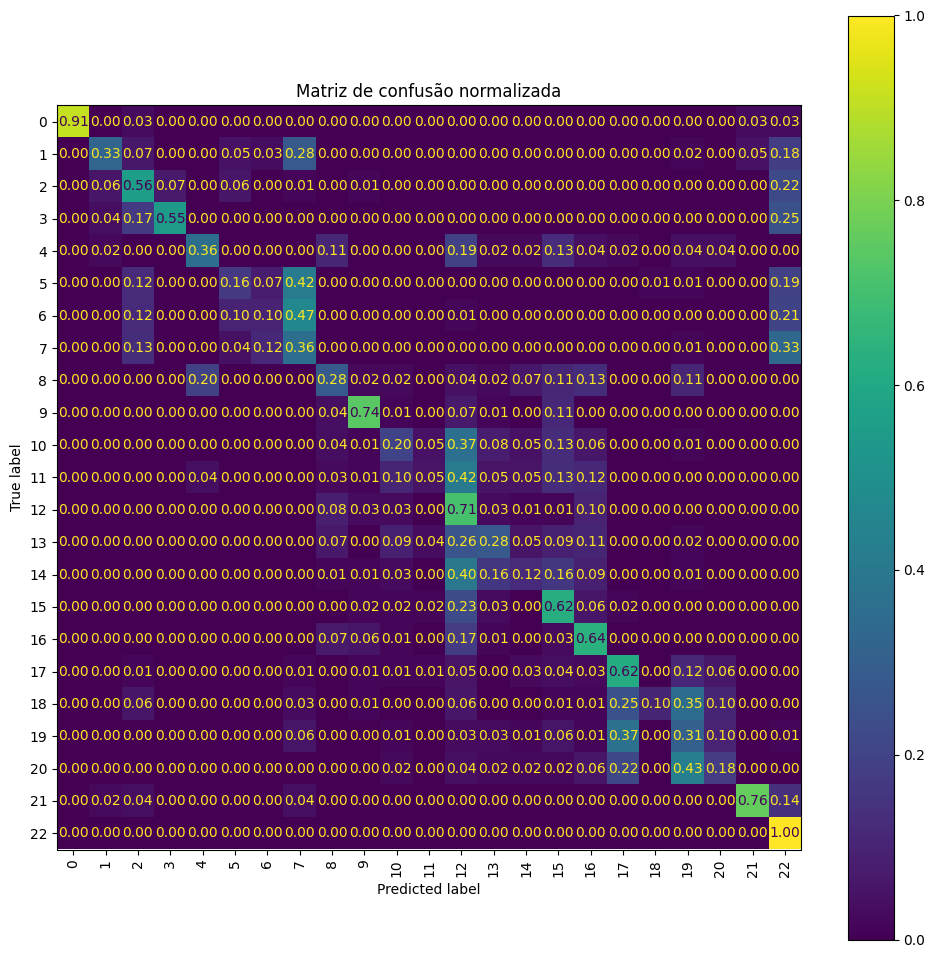

In [51]:
cm_normalized = (
    cm.astype(float)
    /
    (cm.sum(axis=1, keepdims=True) + 1e-12)
)

fig, ax = plt.subplots(
    figsize=(12, 12)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    values_format=".2f"
)

plt.title(
    "Matriz de confusão normalizada"
)

plt.show()

In [52]:
# ============================================================
# EXPERIMENTO 02
# LoRA fixo vs Rank Adaptativo
# ============================================================

import gc
import json
import copy
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from torch import nn
from torchvision.models import vit_b_16, ViT_B_16_Weights
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm


EXPERIMENT_DIR = Path(
    "/content/deepradar_experiment_02"
)

EXPERIMENT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# CONFIGURAÇÕES A COMPARAR
# ============================================================

EXPERIMENTS = [

    {
        "name": "LoRA_r2",
        "method": "fixed",
        "rank": 2
    },

    {
        "name": "LoRA_r4",
        "method": "fixed",
        "rank": 4
    },

    {
        "name": "LoRA_r8",
        "method": "fixed",
        "rank": 8
    },

    {
        "name": "LoRA_r16",
        "method": "fixed",
        "rank": 16
    },

    {
        "name": "LoRA_energy",
        "method": "energy",
        "rank": None
    }

]


# ============================================================
# CRIAR MODELO NOVO
# IMPORTANTE: cada experimento começa do mesmo modelo base
# ============================================================

def create_fresh_model():

    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model = vit_b_16(
        weights=ViT_B_16_Weights.DEFAULT
    )

    # Congelar backbone
    for param in model.parameters():

        param.requires_grad = False


    # Nova cabeça
    in_features = (
        model.heads.head.in_features
    )

    model.heads.head = nn.Linear(
        in_features,
        NUM_CLASSES
    )

    return model


# ============================================================
# AVALIAÇÃO
# ============================================================

@torch.no_grad()
def evaluate_experiment(
    model,
    loader
):

    model.eval()

    y_true = []
    y_pred = []

    for x, labels in loader:

        x = x.to(
            DEVICE,
            non_blocking=True
        )

        logits = model(x)

        pred = (
            logits
            .argmax(dim=1)
            .cpu()
            .numpy()
        )

        y_true.append(
            labels.numpy()
        )

        y_pred.append(
            pred
        )


    y_true = np.concatenate(
        y_true
    )

    y_pred = np.concatenate(
        y_pred
    )


    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro"
    )


    return (
        accuracy,
        macro_f1
    )


# ============================================================
# TREINAMENTO
# ============================================================

def train_experiment(
    model,
    train_loader,
    val_loader,
    epochs
):

    model = model.to(
        DEVICE
    )

    criterion = nn.CrossEntropyLoss()


    optimizer = torch.optim.AdamW(

        [
            p
            for p in model.parameters()
            if p.requires_grad
        ],

        lr=LR,

        weight_decay=WEIGHT_DECAY

    )


    history = []

    best_accuracy = -1

    best_state = None


    for epoch in range(
        1,
        epochs + 1
    ):

        model.train()

        total_loss = 0

        correct = 0

        total = 0


        progress = tqdm(

            train_loader,

            desc=(
                f"Epoch "
                f"{epoch}/{epochs}"
            )

        )


        for x, labels in progress:

            x = x.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )


            optimizer.zero_grad(
                set_to_none=True
            )


            logits = model(
                x
            )


            loss = criterion(
                logits,
                labels
            )


            loss.backward()


            optimizer.step()


            total_loss += (
                loss.item()
                *
                labels.size(0)
            )


            correct += (

                logits.argmax(1)
                ==
                labels

            ).sum().item()


            total += (
                labels.size(0)
            )


        train_loss = (
            total_loss
            /
            total
        )


        train_accuracy = (
            correct
            /
            total
        )


        val_accuracy, val_f1 = (
            evaluate_experiment(
                model,
                val_loader
            )
        )


        epoch_result = {

            "epoch":
                epoch,

            "train_loss":
                train_loss,

            "train_accuracy":
                train_accuracy,

            "val_accuracy":
                val_accuracy,

            "val_macro_f1":
                val_f1

        }


        history.append(
            epoch_result
        )


        print(
            epoch_result
        )


        if (
            val_accuracy
            >
            best_accuracy
        ):

            best_accuracy = (
                val_accuracy
            )

            best_state = copy.deepcopy(
                model.state_dict()
            )


    model.load_state_dict(
        best_state
    )


    return (
        model,
        history
    )

In [53]:
# ============================================================
# EXECUTAR EXPERIMENTOS
# ============================================================

all_results = []


for experiment in EXPERIMENTS:


    print(
        "\n"
        +
        "=" * 70
    )

    print(
        "EXPERIMENTO:",
        experiment["name"]
    )

    print(
        "=" * 70
    )


    # Limpar GPU
    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    # ========================================================
    # MODELO NOVO
    # ========================================================

    model = create_fresh_model()


    # ========================================================
    # DEFINIR RANK
    # ========================================================

    if experiment["method"] == "fixed":


        rank_map = {

            name:
                experiment["rank"]

            for name, module
            in model.named_modules()

            if (
                isinstance(
                    module,
                    nn.Linear
                )

                and

                name.startswith(
                    "encoder.layers"
                )
            )

        }


    elif experiment["method"] == "energy":


        print(
            "Calibrando ranks..."
        )


        gradient_proxies = (
            collect_gradient_proxies(

                model,

                train_loader,

                DEVICE,

                CALIBRATION_BATCHES

            )
        )


        rank_map = {

            name:
                compute_adaptive_rank(

                    matrix,

                    method="energy"

                )

            for name, matrix
            in gradient_proxies.items()

        }


    # ========================================================
    # INSERIR LoRA
    # ========================================================

    replace_linears_with_lora(

        model,

        rank_map

    )


    # ========================================================
    # CONTAR PARÂMETROS
    # ========================================================

    total_params = sum(

        p.numel()

        for p
        in model.parameters()

    )


    trainable_params = sum(

        p.numel()

        for p
        in model.parameters()

        if p.requires_grad

    )


    ranks = list(
        rank_map.values()
    )


    mean_rank = (
        np.mean(ranks)
    )


    print(
        "Rank médio:",
        mean_rank
    )


    print(
        "Parâmetros treináveis:",
        trainable_params
    )


    # ========================================================
    # TREINAR
    # ========================================================

    model, history = (

        train_experiment(

            model,

            train_loader,

            val_loader,

            EPOCHS

        )

    )


    # ========================================================
    # AVALIAÇÃO FINAL
    # ========================================================

    accuracy, macro_f1 = (

        evaluate_experiment(

            model,

            val_loader

        )

    )


    result = {

        "experiment":
            experiment["name"],

        "method":
            experiment["method"],

        "rank":
            experiment["rank"],

        "mean_rank":
            float(mean_rank),

        "accuracy":
            float(accuracy),

        "macro_f1":
            float(macro_f1),

        "trainable_params":
            int(trainable_params),

        "total_params":
            int(total_params),

        "rank_map":
            rank_map,

        "history":
            history

    }


    all_results.append(
        result
    )


    print(
        "\nRESULTADO:"
    )


    print(
        "Accuracy:",
        accuracy
    )


    print(
        "Macro-F1:",
        macro_f1
    )


    # ========================================================
    # SALVAR RESULTADO INDIVIDUAL
    # ========================================================

    result_file = (

        EXPERIMENT_DIR

        /

        (
            experiment["name"]
            +
            ".json"
        )

    )


    with open(

        result_file,

        "w"

    ) as f:

        json.dump(

            result,

            f,

            indent=2

        )


    # Liberar modelo
    del model

    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


EXPERIMENTO: LoRA_r2
Rank médio: 2.0
Parâmetros treináveis: 238871


Epoch 1/3:   0%|          | 0/587 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 1.8287951172871764, 'train_accuracy': 0.3808610400682012, 'val_accuracy': 0.48145780051150894, 'val_macro_f1': 0.4493062796405959}


Epoch 2/3:   0%|          | 0/587 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 1.1436972219722452, 'train_accuracy': 0.5963341858482524, 'val_accuracy': 0.5722506393861893, 'val_macro_f1': 0.54711931484302}


...

{'epoch': 1, 'train_loss': 1.8086043022071208, 'train_accuracy': 0.3864023870417732, 'val_accuracy': 0.5230179028132992, 'val_macro_f1': 0.5019230635902016}


Epoch 2/3:   0%|          | 0/587 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 1.1288722180852704, 'train_accuracy': 0.5973998294970162, 'val_accuracy': 0.5831202046035806, 'val_macro_f1': 0.5709190309165431}


Epoch 3/3:   0%|          | 0/587 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 0.8508683090929485, 'train_accuracy': 0.6890451832907076, 'val_accuracy': 0.6029411764705882, 'val_macro_f1': 0.5855154920397261}

RESULTADO:
Accuracy: 0.6029411764705882
Macro-F1: 0.5855154920397261


In [54]:
# ============================================================
# TABELA FINAL
# ============================================================

summary = pd.DataFrame(

    [

        {

            "Experimento":
                r["experiment"],

            "Rank médio":
                r["mean_rank"],

            "Accuracy":
                r["accuracy"],

            "Macro-F1":
                r["macro_f1"],

            "Parâmetros treináveis":
                r["trainable_params"]

        }

        for r
        in all_results

    ]

)


summary = summary.sort_values(

    "Macro-F1",

    ascending=False

)


display(
    summary
)


summary.to_csv(

    EXPERIMENT_DIR
    /
    "comparison.csv",

    index=False

)

,Experimento,Rank médio,Accuracy,Macro-F1,Parâmetros treináveis
3,LoRA_r16,16.0,0.627877,0.616082,1787159
1,LoRA_r4,4.0,0.604220,0.605932,460055
2,LoRA_r8,8.0,0.622123,0.604008,902423
0,LoRA_r2,2.0,0.607417,0.599001,238871
4,LoRA_energy,4.5,0.602941,0.585515,517655


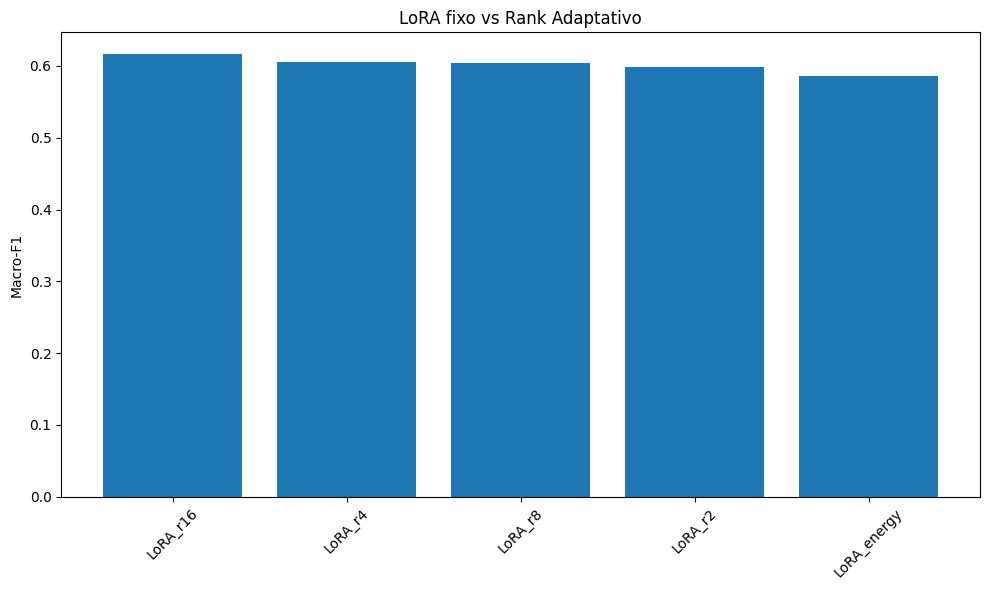

In [55]:
import matplotlib.pyplot as plt


plt.figure(
    figsize=(10, 6)
)


plt.bar(

    summary["Experimento"],

    summary["Macro-F1"]

)


plt.ylabel(
    "Macro-F1"
)


plt.title(
    "LoRA fixo vs Rank Adaptativo"
)


plt.xticks(
    rotation=45
)


plt.tight_layout()


plt.show()

In [57]:
import torch
import math


def compute_gsas_score(
    gradient,
    weight,
    eps=1e-12
):

    G = gradient.detach().float()

    W = weight.detach().float()


    # =====================================
    # SVD do gradiente
    # =====================================

    singular_values = torch.linalg.svdvals(
        G
    )


    # =====================================
    # Distribuição espectral
    # =====================================

    p = (

        singular_values

        /

        (
            singular_values.sum()
            +
            eps
        )

    )


    # =====================================
    # Entropia espectral
    # =====================================

    entropy = -(

        p
        *
        torch.log(
            p + eps
        )

    ).sum()


    # =====================================
    # Effective Rank
    # =====================================

    effective_rank = torch.exp(
        entropy
    )


    # =====================================
    # Força relativa da adaptação
    # =====================================

    gradient_norm = torch.norm(
        G,
        p="fro"
    )


    weight_norm = torch.norm(
        W,
        p="fro"
    )


    relative_gradient = (

        gradient_norm

        /

        (
            weight_norm
            +
            eps
        )

    )


    # =====================================
    # GSAS
    #
    # >>> MÉTRICA PROPOSTA <<<
    # =====================================

    score = (

        effective_rank

        *

        torch.log1p(
            relative_gradient
        )

    )


    return {

        "score":
            score.item(),

        "effective_rank":
            effective_rank.item(),

        "relative_gradient":
            relative_gradient.item()

    }

In [58]:
def compute_all_gsas_scores(
    model,
    gradient_proxies
):

    scores = {}


    modules = dict(
        model.named_modules()
    )


    for name, gradient in gradient_proxies.items():

        layer = modules[name]

        weight = layer.weight


        result = compute_gsas_score(

            gradient,

            weight

        )


        scores[name] = result


    return scores

In [59]:
def scores_to_ranks(
    scores,
    allowed_ranks=(1, 2, 4, 8, 16)
):

    values = [

        data["score"]

        for data
        in scores.values()

    ]


    min_score = min(
        values
    )

    max_score = max(
        values
    )


    rank_map = {}


    for name, data in scores.items():

        score = data[
            "score"
        ]


        normalized = (

            score
            -
            min_score

        ) / (

            max_score
            -
            min_score
            +
            1e-12

        )


        # Converter 0-1
        # para índice dos ranks

        index = round(

            normalized

            *

            (
                len(
                    allowed_ranks
                )
                -
                1
            )

        )


        rank_map[name] = (

            allowed_ranks[
                index
            ]

        )


    return rank_map

In [60]:
import torch
import numpy as np


def compute_gsas_score(
    gradient,
    weight,
    eps=1e-12
):
    """
    GSAS - Gradient Spectral Adaptation Score

    M_l = ER(G_l) * log(1 + ||G_l||_F / ||W_l||_F)
    """

    G = gradient.detach().float().cpu()
    W = weight.detach().float().cpu()

    # ============================
    # Valores singulares
    # ============================

    singular_values = torch.linalg.svdvals(G)

    # ============================
    # Distribuição espectral
    # ============================

    p = (
        singular_values
        /
        (singular_values.sum() + eps)
    )

    # ============================
    # Entropia espectral
    # ============================

    entropy = -(
        p
        *
        torch.log(p + eps)
    ).sum()

    # ============================
    # Effective Rank
    # ============================

    effective_rank = torch.exp(
        entropy
    )

    # ============================
    # Norma relativa do gradiente
    # ============================

    gradient_norm = torch.linalg.norm(G)

    weight_norm = torch.linalg.norm(W)

    relative_gradient = (
        gradient_norm
        /
        (weight_norm + eps)
    )

    # ============================
    # GSAS
    # ============================

    score = (
        effective_rank
        *
        torch.log1p(
            relative_gradient
        )
    )

    return {
        "score": float(score.item()),
        "effective_rank": float(
            effective_rank.item()
        ),
        "relative_gradient": float(
            relative_gradient.item()
        )
    }

In [61]:
def compute_all_gsas_scores(
    model,
    gradient_proxies
):

    modules = dict(
        model.named_modules()
    )

    scores = {}

    for name, gradient in gradient_proxies.items():

        if name not in modules:
            continue

        layer = modules[name]

        if not hasattr(
            layer,
            "weight"
        ):
            continue

        result = compute_gsas_score(

            gradient,

            layer.weight

        )

        scores[name] = result

    return scores

In [62]:
def gsas_scores_to_ranks(
    scores,
    allowed_ranks=(1, 2, 4, 8, 16)
):

    score_values = np.array(

        [
            data["score"]
            for data
            in scores.values()
        ],

        dtype=float

    )


    min_score = (
        score_values.min()
    )

    max_score = (
        score_values.max()
    )


    rank_map = {}


    for name, data in scores.items():

        score = data[
            "score"
        ]


        normalized = (

            score
            -
            min_score

        ) / (

            max_score
            -
            min_score
            +
            1e-12

        )


        index = round(

            normalized

            *

            (
                len(
                    allowed_ranks
                )
                -
                1
            )

        )


        rank_map[name] = int(

            allowed_ranks[
                index
            ]

        )


    return rank_map

In [63]:
import torch
from torch import nn

from torchvision.models import (
    vit_b_16,
    ViT_B_16_Weights
)


def create_gsas_model():

    torch.manual_seed(
        SEED
    )

    if torch.cuda.is_available():

        torch.cuda.manual_seed_all(
            SEED
        )


    model = vit_b_16(

        weights=
        ViT_B_16_Weights.DEFAULT

    )


    # Congelar backbone

    for param in model.parameters():

        param.requires_grad = False


    # Cabeça para DeepRadar

    in_features = (

        model
        .heads
        .head
        .in_features

    )


    model.heads.head = nn.Linear(

        in_features,

        NUM_CLASSES

    )


    return model

In [64]:
# ================================
# Criar modelo
# ================================

model_gsas = create_gsas_model()


# ================================
# Calibrar gradientes
# ================================

print(
    "Coletando gradientes..."
)


gradient_proxies_gsas = (

    collect_gradient_proxies(

        model_gsas,

        train_loader,

        DEVICE,

        CALIBRATION_BATCHES

    )

)


print(
    "Gradientes coletados:",
    len(
        gradient_proxies_gsas
    )
)

Coletando gradientes...
Calibração 1/5
Calibração 2/5
Calibração 3/5
Calibração 4/5
Calibração 5/5
Gradientes coletados: 36


In [65]:
gsas_scores = (

    compute_all_gsas_scores(

        model_gsas,

        gradient_proxies_gsas

    )

)


print(
    "Camadas analisadas:",
    len(
        gsas_scores
    )
)

Camadas analisadas: 36


In [66]:
gsas_rank_map = (

    gsas_scores_to_ranks(

        gsas_scores,

        allowed_ranks=(
            1,
            2,
            4,
            8,
            16
        )

    )

)

In [67]:
for name in gsas_rank_map:

    print(

        name,

        "GSAS =",

        round(
            gsas_scores[
                name
            ][
                "score"
            ],
            6
        ),

        "ER =",

        round(
            gsas_scores[
                name
            ][
                "effective_rank"
            ],
            2
        ),

        "RelGrad =",

        round(
            gsas_scores[
                name
            ][
                "relative_gradient"
            ],
            6
        ),

        "r =",

        gsas_rank_map[
            name
        ]

    )

encoder.layers.encoder_layer_0.self_attention.out_proj GSAS = 1.236854 ER = 39.18 RelGrad = 0.032076 r = 1
encoder.layers.encoder_layer_0.mlp.0 GSAS = 2.417979 ER = 108.32 RelGrad = 0.022573 r = 1
encoder.layers.encoder_layer_0.mlp.3 GSAS = 11.482441 ER = 138.07 RelGrad = 0.086719 r = 8
encoder.layers.encoder_layer_1.self_attention.out_proj GSAS = 2.816566 ER = 80.81 RelGrad = 0.035468 r = 1
encoder.layers.encoder_layer_1.mlp.0 GSAS = 1.711048 ER = 140.16 RelGrad = 0.012283 r = 1
encoder.layers.encoder_layer_1.mlp.3 GSAS = 7.872005 ER = 238.17 RelGrad = 0.033605 r = 4
encoder.layers.encoder_layer_2.self_attention.out_proj GSAS = 5.399241 ER = 124.54 RelGrad = 0.044305 r = 2
encoder.layers.encoder_layer_2.mlp.0 GSAS = 2.734287 ER = 141.75 RelGrad = 0.019476 r = 1
encoder.layers.encoder_layer_2.mlp.3 GSAS = 14.672688 ER = 246.76 RelGrad = 0.061266 r = 16
encoder.layers.encoder_layer_3.self_attention.out_proj GSAS = 8.820693 ER = 143.43 RelGrad = 0.06343 r = 4
encoder.layers.encoder_layer

In [68]:
import pandas as pd
import matplotlib.pyplot as plt


gsas_df = pd.DataFrame(

    [

        {

            "Camada":
                name,

            "GSAS":
                gsas_scores[
                    name
                ][
                    "score"
                ],

            "Effective Rank":
                gsas_scores[
                    name
                ][
                    "effective_rank"
                ],

            "Relative Gradient":
                gsas_scores[
                    name
                ][
                    "relative_gradient"
                ],

            "Rank":
                gsas_rank_map[
                    name
                ]

        }

        for name
        in gsas_rank_map

    ]

)


display(
    gsas_df
)

,Camada,GSAS,Effective Rank,Relative Gradient,Rank
0,encoder.layers.encoder_layer_0.self_attention....,1.236854,39.175804,0.032076,1
1,encoder.layers.encoder_layer_0.mlp.0,2.417979,108.322556,0.022573,1
2,encoder.layers.encoder_layer_0.mlp.3,11.482441,138.071350,0.086719,8
3,encoder.layers.encoder_layer_1.self_attention....,2.816566,80.811821,0.035468,1
4,encoder.layers.encoder_layer_1.mlp.0,1.711048,140.156952,0.012283,1
5,encoder.layers.encoder_layer_1.mlp.3,7.872005,238.166733,0.033605,4
6,encoder.layers.encoder_layer_2.self_attention....,5.399241,124.544212,0.044305,2
7,encoder.layers.encoder_layer_2.mlp.0,2.734287,141.751816,0.019476,1
8,encoder.layers.encoder_layer_2.mlp.3,14.672688,246.755524,0.061266,16
9,encoder.layers.encoder_layer_3.self_attention....,8.820693,143.426300,0.063430,4


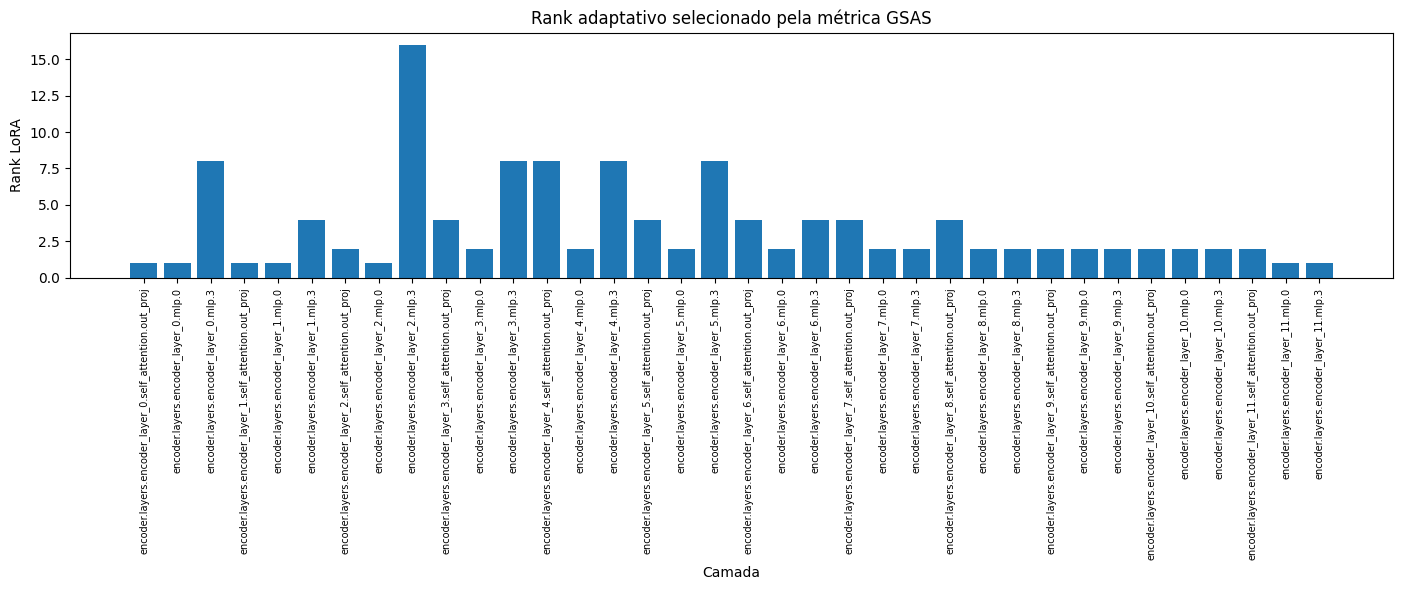

In [69]:
plt.figure(
    figsize=(14, 6)
)


plt.bar(

    range(
        len(
            gsas_df
        )
    ),

    gsas_df[
        "Rank"
    ]

)


plt.xlabel(
    "Camada"
)


plt.ylabel(
    "Rank LoRA"
)


plt.title(
    "Rank adaptativo selecionado pela métrica GSAS"
)


plt.xticks(

    range(
        len(
            gsas_df
        )
    ),

    gsas_df[
        "Camada"
    ],

    rotation=90,

    fontsize=7

)


plt.tight_layout()

plt.show()

In [70]:
replace_linears_with_lora(

    model_gsas,

    gsas_rank_map

)

In [75]:
total_params_gsas = sum(

    p.numel()

    for p
    in model_gsas.parameters()

)


trainable_params_gsas = sum(

    p.numel()

    for p
    in model_gsas.parameters()

    if p.requires_grad

)


print(
    "Parâmetros totais:",
    total_params_gsas
)


print(
    "Parâmetros treináveis:",
    trainable_params_gsas
)


print(
    "Percentual treinável:",
    100
    *
    trainable_params_gsas
    /
    total_params_gsas
)


print(
    "Rank médio:",
    np.mean(
        list(
            gsas_rank_map.values()
        )
    )
)

Parâmetros totais: 86201111
Parâmetros treináveis: 402455
Percentual treinável: 0.466879133379151
Rank médio: 3.4166666666666665


In [76]:
model_gsas = model_gsas.to(
    DEVICE
)


xb, yb = next(
    iter(
        train_loader
    )
)


xb = xb.to(
    DEVICE
)


with torch.no_grad():

    output = model_gsas(
        xb
    )


print(
    "Input:",
    xb.shape
)


print(
    "Output:",
    output.shape
)

Input: torch.Size([8, 3, 224, 224])
Output: torch.Size([8, 23])


In [72]:
model_gsas, history_gsas = (

    train_experiment(

        model_gsas,

        train_loader,

        val_loader,

        EPOCHS

    )

)

Epoch 1/3:   0%|          | 0/587 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 1.8398228881202594, 'train_accuracy': 0.37851662404092073, 'val_accuracy': 0.48657289002557547, 'val_macro_f1': 0.44892224113039403}


Epoch 2/3:   0%|          | 0/587 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 1.1632177912569006, 'train_accuracy': 0.5942028985507246, 'val_accuracy': 0.571611253196931, 'val_macro_f1': 0.555771255563014}


Epoch 3/3:   0%|          | 0/587 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 0.8964358848429905, 'train_accuracy': 0.6764705882352942, 'val_accuracy': 0.6080562659846548, 'val_macro_f1': 0.5978534542609638}


In [77]:
accuracy_gsas, macro_f1_gsas = (

    evaluate_experiment(

        model_gsas,

        val_loader

    )

)


print(
    "GSAS Accuracy:",
    accuracy_gsas
)


print(
    "GSAS Macro-F1:",
    macro_f1_gsas
)

GSAS Accuracy: 0.6080562659846548
GSAS Macro-F1: 0.5978534542609638


In [78]:
import json
from pathlib import Path


GSAS_DIR = Path(

    "/content/deepradar_gsas"

)


GSAS_DIR.mkdir(

    parents=True,

    exist_ok=True

)


gsas_result = {

    "method":
        "GSAS",

    "accuracy":
        float(
            accuracy_gsas
        ),

    "macro_f1":
        float(
            macro_f1_gsas
        ),

    "mean_rank":
        float(

            np.mean(

                list(

                    gsas_rank_map.values()

                )

            )

        ),

    "trainable_params":
        int(
            trainable_params_gsas
        ),

    "total_params":
        int(
            total_params_gsas
        ),

    "rank_map":
        gsas_rank_map,

    "gsas_scores":
        gsas_scores,

    "history":
        history_gsas

}


with open(

    GSAS_DIR
    /
    "gsas_results.json",

    "w"

) as f:

    json.dump(

        gsas_result,

        f,

        indent=2

    )


print(
    "Resultado salvo em:",
    GSAS_DIR
)

Resultado salvo em: /content/deepradar_gsas


In [79]:
##########

In [80]:
def lora_parameter_cost(
    layer,
    rank
):
    """
    Número de parâmetros LoRA:

    A: rank * in_features
    B: out_features * rank
    """

    return int(

        rank
        *
        (
            layer.in_features
            +
            layer.out_features
        )

    )

In [81]:
budget_model = create_gsas_model()


modules = dict(
    budget_model.named_modules()
)


BASELINE_RANK = 8


baseline_budget = 0


for name in gsas_scores:

    layer = modules[
        name
    ]

    baseline_budget += (

        lora_parameter_cost(

            layer,

            BASELINE_RANK

        )

    )


print(
    "Orçamento equivalente ao LoRA r=8:"
)


print(
    baseline_budget,
    "parâmetros LoRA"
)

Orçamento equivalente ao LoRA r=8:
884736 parâmetros LoRA


In [82]:
def normalize_gsas_scores(
    gsas_scores
):

    total_score = sum(

        data["score"]

        for data
        in gsas_scores.values()

    )


    normalized = {}


    for name, data in gsas_scores.items():

        normalized[
            name
        ] = (

            data["score"]

            /

            (
                total_score
                +
                1e-12
            )

        )


    return normalized

In [83]:
normalized_gsas = (

    normalize_gsas_scores(

        gsas_scores

    )

)

In [84]:
ALLOWED_RANKS = [

    1,
    2,
    4,
    8,
    16

]

In [85]:
def allocate_rank_budget(
    model,
    gsas_scores,
    total_budget,
    allowed_ranks=(1, 2, 4, 8, 16)
):

    modules = dict(
        model.named_modules()
    )


    # =====================================
    # Rank mínimo para todas as camadas
    # =====================================

    rank_map = {

        name:
            allowed_ranks[0]

        for name
        in gsas_scores

    }


    # =====================================
    # Custo inicial
    # =====================================

    current_cost = 0


    for name, rank in rank_map.items():

        layer = modules[
            name
        ]


        current_cost += (

            lora_parameter_cost(

                layer,

                rank

            )

        )


    print(
        "Custo inicial:",
        current_cost
    )


    print(
        "Budget:",
        total_budget
    )


    # =====================================
    # Distribuição gulosa do orçamento
    # =====================================

    while True:


        candidates = []


        for name in rank_map:


            current_rank = rank_map[
                name
            ]


            current_index = (

                allowed_ranks.index(

                    current_rank

                )

            )


            # Já está no máximo

            if (

                current_index

                ==

                len(
                    allowed_ranks
                )
                -
                1

            ):

                continue


            next_rank = (

                allowed_ranks[

                    current_index
                    +
                    1

                ]

            )


            layer = modules[
                name
            ]


            current_layer_cost = (

                lora_parameter_cost(

                    layer,

                    current_rank

                )

            )


            next_layer_cost = (

                lora_parameter_cost(

                    layer,

                    next_rank

                )

            )


            delta_cost = (

                next_layer_cost

                -

                current_layer_cost

            )


            delta_rank = (

                next_rank

                -

                current_rank

            )


            score = (

                gsas_scores[
                    name
                ][
                    "score"
                ]

            )


            # =================================
            # Utilidade por parâmetro adicional
            # =================================

            utility = (

                score

                *
                delta_rank

                /

                (
                    delta_cost
                    +
                    1e-12
                )

            )


            candidates.append(

                (

                    utility,

                    name,

                    next_rank,

                    delta_cost

                )

            )


        if not candidates:

            break


        # Maior utilidade primeiro

        candidates.sort(

            reverse=True,

            key=lambda x:
                x[0]

        )


        allocated = False


        for (

            utility,

            name,

            next_rank,

            delta_cost

        ) in candidates:


            if (

                current_cost

                +
                delta_cost

                <=

                total_budget

            ):


                rank_map[
                    name
                ] = next_rank


                current_cost += (

                    delta_cost

                )


                allocated = True


                break


        if not allocated:

            break


    return (

        rank_map,

        current_cost

    )

In [86]:
budget_model = (

    create_gsas_model()

)


gsas_budget_rank_map, used_budget = (

    allocate_rank_budget(

        budget_model,

        gsas_scores,

        baseline_budget,

        allowed_ranks=(

            1,
            2,
            4,
            8,
            16

        )

    )

)

Custo inicial: 110592
Budget: 884736


In [87]:
print(
    "Budget disponível:",
    baseline_budget
)


print(
    "Budget utilizado:",
    used_budget
)


print(
    "Utilização:",
    100
    *
    used_budget
    /
    baseline_budget,
    "%"
)


print(
    "Rank médio:",
    np.mean(

        list(

            gsas_budget_rank_map.values()

        )

    )
)

Budget disponível: 884736
Budget utilizado: 883968
Utilização: 99.91319444444444 %
Rank médio: 9.36111111111111


In [88]:
import pandas as pd


budget_df = pd.DataFrame(

    [

        {

            "Camada":
                name,

            "GSAS":
                gsas_scores[
                    name
                ][
                    "score"
                ],

            "Rank":
                gsas_budget_rank_map[
                    name
                ]

        }

        for name
        in gsas_budget_rank_map

    ]

)


budget_df = (

    budget_df

    .sort_values(

        "GSAS",

        ascending=False

    )

)


display(
    budget_df
)

,Camada,GSAS,Rank
8,encoder.layers.encoder_layer_2.mlp.3,14.672688,16
11,encoder.layers.encoder_layer_3.mlp.3,12.525872,16
14,encoder.layers.encoder_layer_4.mlp.3,12.005776,16
2,encoder.layers.encoder_layer_0.mlp.3,11.482441,16
17,encoder.layers.encoder_layer_5.mlp.3,10.253731,16
12,encoder.layers.encoder_layer_4.self_attention....,9.824225,16
15,encoder.layers.encoder_layer_5.self_attention....,9.422112,16
18,encoder.layers.encoder_layer_6.self_attention....,9.221016,16
24,encoder.layers.encoder_layer_8.self_attention....,8.986683,16
9,encoder.layers.encoder_layer_3.self_attention....,8.820693,16


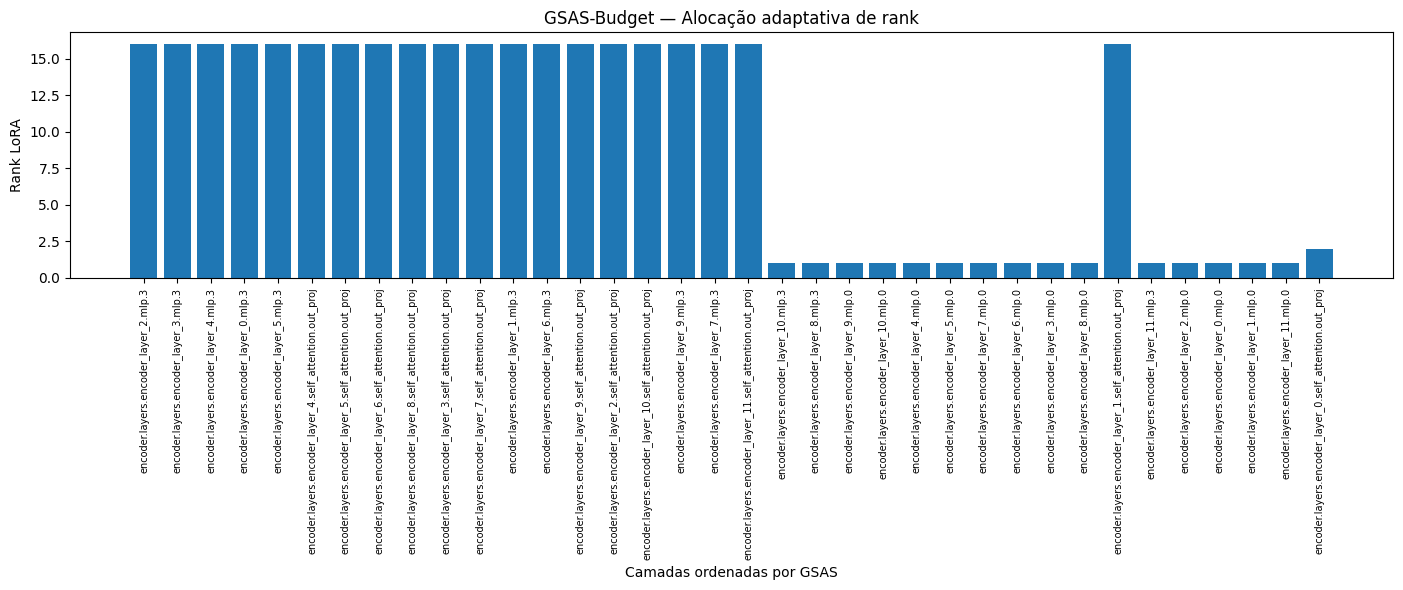

In [89]:
import matplotlib.pyplot as plt


plt.figure(
    figsize=(14, 6)
)


plt.bar(

    range(
        len(
            budget_df
        )
    ),

    budget_df[
        "Rank"
    ]

)


plt.xlabel(
    "Camadas ordenadas por GSAS"
)


plt.ylabel(
    "Rank LoRA"
)


plt.title(
    "GSAS-Budget — Alocação adaptativa de rank"
)


plt.xticks(

    range(
        len(
            budget_df
        )
    ),

    budget_df[
        "Camada"
    ],

    rotation=90,

    fontsize=7

)


plt.tight_layout()


plt.show()

In [90]:
model_gsas_budget = (

    create_gsas_model()

)

In [91]:
replace_linears_with_lora(

    model_gsas_budget,

    gsas_budget_rank_map

)

In [92]:
total_params_budget = sum(

    p.numel()

    for p
    in model_gsas_budget.parameters()

)


trainable_params_budget = sum(

    p.numel()

    for p
    in model_gsas_budget.parameters()

    if p.requires_grad

)


print(
    "Parâmetros totais:",
    total_params_budget
)


print(
    "Parâmetros treináveis:",
    trainable_params_budget
)

Parâmetros totais: 86700311
Parâmetros treináveis: 901655


In [93]:
model_gsas_budget, history_gsas_budget = (

    train_experiment(

        model_gsas_budget,

        train_loader,

        val_loader,

        EPOCHS

    )

)

Epoch 1/3:   0%|          | 0/587 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 1.8422787643759453, 'train_accuracy': 0.3744671781756181, 'val_accuracy': 0.46675191815856776, 'val_macro_f1': 0.4393660134368783}


Epoch 2/3:   0%|          | 0/587 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 1.1391898998061714, 'train_accuracy': 0.5999573742540495, 'val_accuracy': 0.5575447570332481, 'val_macro_f1': 0.5421781125175208}


Epoch 3/3:   0%|          | 0/587 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 0.8935646347682494, 'train_accuracy': 0.6732736572890026, 'val_accuracy': 0.6093350383631714, 'val_macro_f1': 0.6049217411699596}


In [98]:
accuracy_budget, macro_f1_budget = (

    evaluate_experiment(

        model_gsas_budget,

        val_loader

    )

)


print(
    "GSAS-Budget Accuracy:",
    accuracy_budget
)


print(
    "GSAS-Budget Macro-F1:",
    macro_f1_budget
)

GSAS-Budget Accuracy: 0.6093350383631714
GSAS-Budget Macro-F1: 0.6049217411699596


In [99]:
comparison_budget = pd.DataFrame(

    [

        {

            "Método":
                "GSAS",

            "Rank médio":
                np.mean(

                    list(

                        gsas_rank_map.values()

                    )

                ),

            "Accuracy":
                accuracy_gsas,

            "Macro-F1":
                macro_f1_gsas,

            "Parâmetros":
                trainable_params_gsas

        },


        {

            "Método":
                "GSAS-Budget",

            "Rank médio":
                np.mean(

                    list(

                        gsas_budget_rank_map.values()

                    )

                ),

            "Accuracy":
                accuracy_budget,

            "Macro-F1":
                macro_f1_budget,

            "Parâmetros":
                trainable_params_budget

        }

    ]

)


display(
    comparison_budget
)

,Método,Rank médio,Accuracy,Macro-F1,Parâmetros
0,GSAS,3.416667,0.608056,0.597853,402455
1,GSAS-Budget,9.361111,0.609335,0.604922,901655
